In [1]:
import pandas as pd

df = pd.read_csv("transactions.csv")

In [2]:
df.head()

,transaction_id,transaction_date,branch_id,department_id,account_code,account_type,amount_inr,entry_type,customer_id,vendor_id,document_reference,status
0,TX000000001,01-01-2025,BR001,D001,Revenue,Revenue,93182.63,Credit,C01352,NaN,SALES-000000001,Posted
1,TX000000002,01-01-2025,BR001,D001,Revenue,Revenue,121159.96,Credit,C01364,NaN,SALES-000000002,Posted
2,TX000000003,01-01-2025,BR001,D001,Revenue,Revenue,126723.95,Credit,C00096,NaN,SALES-000000003,Posted
3,TX000000004,01-01-2025,BR001,D002,COGS,Cost of Goods Sold,72016.36,Credit,NaN,V00003,BILL-000000004,Posted
4,TX000000005,01-01-2025,BR001,D005,Salary,Operating Expense,197966.73,Credit,NaN,V00734,BILL-000000005,Posted


In [3]:
df.shape

(20075, 12)

In [4]:
df.columns

Index(['transaction_id', 'transaction_date', 'branch_id', 'department_id',
       'account_code', 'account_type', 'amount_inr', 'entry_type',
       'customer_id', 'vendor_id', 'document_reference', 'status'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20075 entries, 0 to 20074
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   transaction_id      20075 non-null  object 
 1   transaction_date    20075 non-null  object 
 2   branch_id           20075 non-null  object 
 3   department_id       20075 non-null  object 
 4   account_code        20075 non-null  object 
 5   account_type        20075 non-null  object 
 6   amount_inr          20075 non-null  float64
 7   entry_type          20075 non-null  object 
 8   customer_id         8215 non-null   object 
 9   vendor_id           11860 non-null  object 
 10  document_reference  20075 non-null  object 
 11  status              20075 non-null  object 
dtypes: float64(1), object(11)
memory usage: 1.8+ MB


In [6]:
df.isnull().sum()

transaction_id            0
transaction_date          0
branch_id                 0
department_id             0
account_code              0
account_type              0
amount_inr                0
entry_type                0
customer_id           11860
vendor_id              8215
document_reference        0
status                    0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.describe()

,amount_inr
count,20075.000000
mean,64826.630804
std,44269.603047
min,1500.000000
25%,26099.655000
50%,62979.590000
75%,86403.360000
max,260837.380000


In [9]:
df["transaction_date"]=pd.to_datetime(
    df["transaction_date"],
    format="%d-%m-%Y"
)

In [10]:
revenue_df = df[df["account_type"]=="Revenue"]

monthly_revenue = revenue_df.groupby(
    revenue_df["transaction_date"].dt.to_period("M")
)["amount_inr"].sum()
monthly_revenue

transaction_date
2025-01    30604823.51
2025-02    25769078.86
2025-03    31604624.58
2025-04    27281318.99
2025-05    26647365.45
2025-06    29205478.08
2025-07    27535643.92
2025-08    27524224.18
2025-09    29393796.58
2025-10    31203905.21
2025-11    26581866.65
2025-12    28761974.36
2026-01    31559922.81
2026-02    29160850.23
2026-03    29958405.47
2026-04    29763936.62
2026-05    32747818.40
2026-06    32209433.07
2026-07    33607661.63
2026-08    34727059.99
2026-09    29782989.34
2026-10    28987835.21
Freq: M, Name: amount_inr, dtype: float64

<Axes: title={'center': 'Monthly Revenue Trend'}, xlabel='transaction_date'>

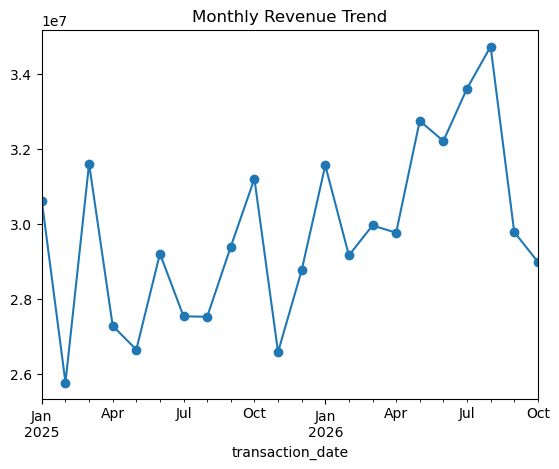

In [14]:
monthly_revenue.plot(
    kind="line",
    title="Monthly Revenue Trend",
    marker="o"
)

In [15]:
monthly_revenue.idxmax()

Period('2026-08', 'M')

In [16]:
monthly_revenue.max()

34727059.99

In [17]:
monthly_revenue.idxmin()

Period('2025-02', 'M')

In [18]:
monthly_revenue.min()

25769078.86

In [21]:
top_months= monthly_revenue.sort_values(ascending=False).head(5)
top_months

transaction_date
2026-08    34727059.99
2026-07    33607661.63
2026-05    32747818.40
2026-06    32209433.07
2025-03    31604624.58
Freq: M, Name: amount_inr, dtype: float64

<Axes: title={'center': 'Top 5 Revenue Months'}, xlabel='transaction_date'>

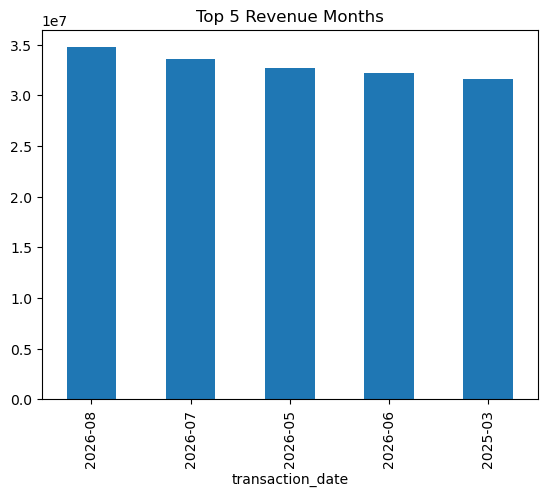

In [22]:
top_months.plot(
    kind="bar",
    title = "Top 5 Revenue Months"
)

In [23]:
df["account_type"].value_counts()

account_type
Operating Expense     8302
Revenue               8215
Cost of Goods Sold    1186
Depreciation          1186
Finance Cost          1186
Name: count, dtype: int64

In [24]:
expense_df = df[df["account_type"]=="Operating Expense"]
expense_df.head(5)

,transaction_id,transaction_date,branch_id,department_id,account_code,account_type,amount_inr,entry_type,customer_id,vendor_id,document_reference,status
4,TX000000005,2025-01-01,BR001,D005,Salary,Operating Expense,197966.73,Credit,NaN,V00734,BILL-000000005,Posted
5,TX000000006,2025-01-01,BR001,D002,Rent,Operating Expense,97958.01,Credit,NaN,V00797,BILL-000000006,Posted
6,TX000000007,2025-01-01,BR001,D003,Marketing,Operating Expense,66077.05,Credit,NaN,V00600,BILL-000000007,Posted
7,TX000000008,2025-01-01,BR001,D002,Utilities,Operating Expense,24098.43,Credit,NaN,V00715,BILL-000000008,Posted
8,TX000000009,2025-01-01,BR001,D002,Logistics,Operating Expense,44103.13,Credit,NaN,V00663,BILL-000000009,Posted


In [25]:
expense_df["amount_inr"].sum()

np.float64(513674860.81000006)

In [28]:
expense_df["account_code"].value_counts().head(10)

account_code
Salary               1186
Rent                 1186
Marketing            1186
Utilities            1186
Logistics            1186
Professional Fees    1186
IT Expense           1186
Name: count, dtype: int64

In [41]:
expense_df.groupby("account_code")["amount_inr"].sum().round(1)

account_code
IT Expense            25570080.8
Logistics             47896779.0
Marketing             66271031.3
Professional Fees     20627320.5
Rent                 100337010.8
Salary               226137240.6
Utilities             26835397.9
Name: amount_inr, dtype: float64

<Axes: title={'center': 'Operating Expense by Category'}, xlabel='account_code'>

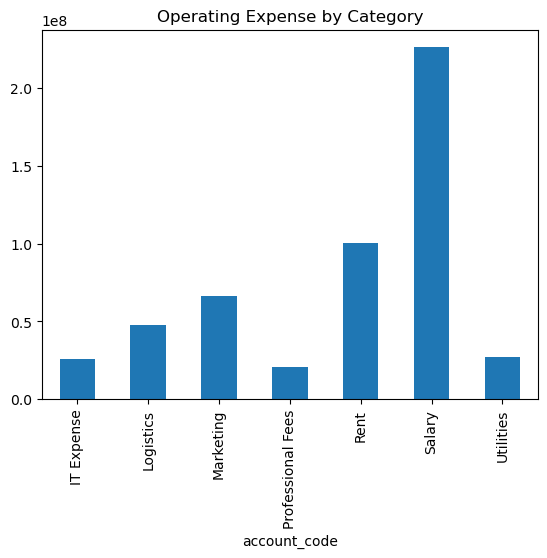

In [30]:
expense_df.groupby("account_code")["amount_inr"].sum().plot(
    kind="bar",
    title="Operating Expense by Category"
)

In [34]:
revenue_by_branch = revenue_df.groupby("branch_id")["amount_inr"].sum().sort_values(ascending=False)
revenue_by_branch

branch_id
BR007    78518233.40
BR005    74715531.12
BR001    72984688.72
BR002    69626274.34
BR003    66734588.52
BR008    64115380.31
BR006    60077281.41
BR009    59544552.34
BR004    56733981.19
BR010    51569501.79
Name: amount_inr, dtype: float64

In [35]:
expense_by_branch = expense_df.groupby("branch_id")["amount_inr"].sum().sort_values(ascending=False)

expense_by_branch

branch_id
BR007    60510852.94
BR001    60140904.03
BR005    57484440.75
BR003    57073746.74
BR002    53360244.22
BR009    47786771.76
BR006    47423131.68
BR008    46602129.68
BR004    44307986.36
BR010    38984652.65
Name: amount_inr, dtype: float64

In [36]:
branch_profit = revenue_by_branch - expense_by_branch

branch_profit.sort_values(ascending=False)

branch_id
BR007    18007380.46
BR008    17513250.63
BR005    17231090.37
BR002    16266030.12
BR001    12843784.69
BR006    12654149.73
BR010    12584849.14
BR004    12425994.83
BR009    11757780.58
BR003     9660841.78
Name: amount_inr, dtype: float64

In [40]:
df.groupby("account_type")["amount_inr"].sum().round(1)

account_type
Cost of Goods Sold     87988669.0
Depreciation           31740181.8
Finance Cost           13370888.7
Operating Expense     513674860.8
Revenue               654620013.1
Name: amount_inr, dtype: float64

In [42]:
df["status"].value_counts()

status
Posted    20075
Name: count, dtype: int64